# Rfm analysis-Edalet Sadigov

## Libraries

In [2]:
from common import *

sns.set_theme(style='whitegrid')
print('All libraries are ready to use.')

All libraries are ready to use.


## Loading Dataset and First look

In [3]:
raw_data = pd.read_csv('rfm_sales.csv')

In [4]:
raw_data.head(5)

,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,...,ADDRESSLINE1,ADDRESSLINE2,CITY,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,104396,4,76.30,1,305.20,2022-01-01,Shipped,1,1,2022,...,4879 King St.,Building C,New Bedford,NY,39125,USA,NaN,Nelson,Armand,Small
1,104396,5,169.68,2,848.40,2022-01-01,Shipped,1,1,2022,...,4879 King St.,Building C,New Bedford,NY,39125,USA,NaN,Nelson,Armand,Small
2,105216,1,73.37,1,73.37,2022-01-01,Shipped,1,1,2022,...,8669 Washington St.,Building C,NYC,CA,62462,USA,NaN,Pedro,Julie,Small
3,105216,3,97.39,2,292.17,2022-01-01,Shipped,1,1,2022,...,8669 Washington St.,Building C,NYC,CA,62462,USA,NaN,Pedro,Julie,Small
4,105216,3,136.60,3,409.80,2022-01-01,Shipped,1,1,2022,...,8669 Washington St.,Building C,NYC,CA,62462,USA,NaN,Pedro,Julie,Small


In [5]:
print(f'Column count: {raw_data.shape[1]}')
print(f'Raw count: {raw_data.shape[0]}')

Column count: 25
Raw count: 500000


## 1. Data Overview and Cleaning

In [6]:
df = raw_data.copy()
df.columns = df.columns.str.strip().str.lower()
df = df.rename(columns={'customername': 'customer_name', 'ordernumber': 'order_number', 'orderdate': 'order_date'})
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500000 entries, 0 to 499999
Data columns (total 25 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   order_number      500000 non-null  int64  
 1   quantityordered   500000 non-null  int64  
 2   priceeach         500000 non-null  float64
 3   orderlinenumber   500000 non-null  int64  
 4   sales             500000 non-null  float64
 5   order_date        500000 non-null  str    
 6   status            500000 non-null  str    
 7   qtr_id            500000 non-null  int64  
 8   month_id          500000 non-null  int64  
 9   year_id           500000 non-null  int64  
 10  productline       500000 non-null  str    
 11  msrp              500000 non-null  float64
 12  productcode       500000 non-null  str    
 13  customer_name     500000 non-null  str    
 14  phone             500000 non-null  str    
 15  addressline1      500000 non-null  str    
 16  addressline2      231901 non-nu

In [7]:
df.describe().round(2)

,order_number,quantityordered,priceeach,orderlinenumber,sales,qtr_id,month_id,year_id,msrp
count,500000.00,500000.00,500000.00,500000.00,500000.00,500000.00,500000.00,500000.00,500000.00
mean,175386.10,3.54,87.63,2.43,310.59,2.60,6.80,2023.89,93.47
std,43508.01,3.64,39.36,1.34,378.06,1.14,3.51,1.13,41.37
min,101000.00,1.00,22.60,1.00,22.60,1.00,1.00,2022.00,30.14
25%,137559.00,1.00,55.83,1.00,107.38,2.00,4.00,2023.00,59.31
50%,175272.00,2.00,83.82,2.00,201.21,3.00,7.00,2024.00,91.84
75%,213045.00,4.00,110.28,3.00,377.32,4.00,10.00,2025.00,116.36
max,250999.00,50.00,216.82,6.00,10458.50,4.00,12.00,2025.00,212.57


`sales` is right-skewed: the mean is higher than the median (see `50%`), so a few large order lines pull the average up. This is the first sign that quantile (rank-based) scoring will be safer than fixed thresholds.

In [ ]:
null_summary = pd.DataFrame({'null_count': df.isnull().sum(), 'null_%': (df.isnull().mean() * 100).round(1)})
print(null_summary[null_summary['null_count'] > 0])


              null_count  null_%
addressline2      268099    53.6
state             153570    30.7
territory         278957    55.8

Duplicate rows   : 0
Order lines      : 500,000
Unique orders    : 150,000
Unique customers : 25,097


In [ ]:
print(f'Duplicate rows   : {df.duplicated().sum():,}')
print(f'Order lines      : {len(df):,}')
print(f'Unique orders    : {df["order_number"].nunique():,}')
print(f'Unique customers : {df["customer_name"].nunique():,}')

Only `addressline2`, `state` and `territory` contain nulls — none of them is used in RFM, so they are left untouched. There are no duplicate rows.



RFM is built on three columns: `customer_name` (who), `order_number` / `order_date` (when and how often) and `sales` (how much). Before using them, three assumptions must hold: one order belongs to one customer, one date and one status. Otherwise `nunique(order_number)` would not mean "number of orders".

In [ ]:
order_check = df.groupby('order_number').agg(
    customers=('customer_name', 'nunique'),
    dates=('order_date', 'nunique'),
    statuses=('status', 'nunique'),
    order_sales=('sales', 'sum'),
    status=('status', 'first'),
).reset_index()


Max customers per order : 1
Max dates per order     : 1
Max statuses per order  : 1


In [ ]:

print(f'Max customers per order : {order_check["customers"].max()}')
print(f'Max dates per order     : {order_check["dates"].max()}')
print(f'Max statuses per order  : {order_check["statuses"].max()}')

The maximum is 1 for all three, so the order is a clean unit and the status can be filtered at order level.

In [ ]:
df['order_date'] = pd.to_datetime(df['order_date'], format='%Y-%m-%d')

Date range                  : 2022-01-01 -> 2025-12-31
Max |sales - qty * price|   : 0.000000
Non-positive sales / qty    : 0 / 0


In [ ]:
sales_gap = (df['sales'] - df['quantityordered'] * df['priceeach']).abs()
print(f'Date range                  : {df["order_date"].min().date()} -> {df["order_date"].max().date()}')
print(f'Max |sales - qty * price|   : {sales_gap.max():.6f}')
print(f'Non-positive sales / qty    : {(df["sales"] <= 0).sum()} / {(df["quantityordered"] <= 0).sum()}')

In [11]:
status_summary = order_check.groupby('status').agg(orders=('order_number', 'count'), sales=('order_sales', 'sum')).reset_index()
status_summary['order_share_%'] = (status_summary['orders'] / status_summary['orders'].sum() * 100).round(2)
status_summary['sales_share_%'] = (status_summary['sales'] / status_summary['sales'].sum() * 100).round(2)
status_summary.sort_values('orders', ascending=False)

,status,orders,sales,order_share_%,sales_share_%
5,Shipped,133527,1.383252e+08,89.02,89.07
4,Resolved,5945,6.076895e+06,3.96,3.91
0,Cancelled,3080,3.205709e+06,2.05,2.06
3,On Hold,3008,3.142376e+06,2.01,2.02
2,In Process,2931,3.010776e+06,1.95,1.94
1,Disputed,1509,1.532961e+06,1.01,0.99


**Cleaning decision — exclude `Cancelled` orders.** There are **3,080** cancelled orders (**2.1%** of orders, **2.1%** of sales). A cancelled order is not a purchase: counting it would raise Frequency and Monetary and would reset Recency for a customer who actually received nothing. All other statuses (`Shipped`, `Resolved`, `In Process`, `On Hold`, `Disputed`) are kept because the customer did place and keep the order; `Disputed` is flagged as a limitation in the final summary.

In [12]:
rfm_data = df[df['status'] != 'Cancelled'].copy()

print(f'Before cleaning  : {len(df):,} lines | {df["customer_name"].nunique():,} customers | ${df["sales"].sum():,.0f}')
print(f'After cleaning   : {len(rfm_data):,} lines | {rfm_data["customer_name"].nunique():,} customers | ${rfm_data["sales"].sum():,.0f}')
print(f'Reduced row count: {len(df) - len(rfm_data):,}')
print(f'Customers dropped: {df["customer_name"].nunique() - rfm_data["customer_name"].nunique():,} (had only cancelled orders)')

Before cleaning  : 500,000 lines | 25,097 customers | $155,293,902
After cleaning   : 489,603 lines | 24,916 customers | $152,088,192
Reduced row count: 10,397
Customers dropped: 181 (had only cancelled orders)


**181** customers disappear because all of their orders were cancelled; they have no purchase history, so they cannot be scored. The RFM table below contains **24,916** customers.

## 2. RFM Calculation

**Reference date** = last order date in the data + 1 day, so that a customer who bought on the final day has `recency = 1`, not 0.

- **Recency** — days between the reference date and the customer's last order (lower = better)
- **Frequency** — number of **unique** `order_number` values (one order has several lines, so counting rows would overstate it)
- **Monetary** — sum of `sales` over all kept lines

In [ ]:
reference_date = rfm_data['order_date'].max() + pd.Timedelta(days=1)
print(f'Reference date : {reference_date.date()}')


Reference date : 2026-01-01


,customer_name,last_order_date,recency,frequency,monetary
0,Cust_00002 Classic Creations,2024-10-10,448,2,4834.98
1,Cust_00003 Auto Imports,2025-06-21,194,1,1225.54
2,Cust_00005 Vintage Toys,2025-10-06,87,4,4123.93
3,Cust_00008 Prime Creations,2025-12-11,21,43,36180.23
4,Cust_00009 Euro Diecast,2025-06-09,206,3,1837.69


In [ ]:

rfm = rfm_data.groupby('customer_name').agg(
    last_order_date=('order_date', 'max'),
    frequency=('order_number', 'nunique'),
    monetary=('sales', 'sum'),
).reset_index()


In [ ]:

rfm['recency'] = (reference_date - rfm['last_order_date']).dt.days
rfm = rfm[['customer_name', 'last_order_date', 'recency', 'frequency', 'monetary']]
rfm.head()

In [14]:
print(f'Customers in RFM table : {len(rfm):,}')
print(f'Nulls                   : {int(rfm.isnull().sum().sum())}')
print(f'Recency   min / max     : {rfm["recency"].min()} / {rfm["recency"].max()} days')
print(f'Frequency min / max     : {rfm["frequency"].min()} / {rfm["frequency"].max():,} orders')
print(f'Monetary  min / max     : ${rfm["monetary"].min():,.2f} / ${rfm["monetary"].max():,.2f}')
print()
rfm[['recency', 'frequency', 'monetary']].describe(percentiles=[.25, .5, .75, .9, .99]).round(1)

Customers in RFM table : 24,916
Nulls                   : 0
Recency   min / max     : 1 / 1461 days
Frequency min / max     : 1 / 11,804 orders
Monetary  min / max     : $25.62 / $13,240,046.58



,recency,frequency,monetary
count,24916.0,24916.0,24916.0
mean,334.7,5.9,6104.0
std,359.6,78.9,88505.7
min,1.0,1.0,25.6
25%,72.0,1.0,1021.8
50%,201.0,2.0,2229.6
75%,435.0,5.0,4921.6
90%,937.0,10.0,10231.0
99%,1402.0,49.0,51359.8
max,1461.0,11804.0,13240046.6


All checks pass: `recency` starts at 1, `frequency` starts at 1, `monetary` is positive and there are no nulls.

The three metrics are strongly right-skewed. The mean Monetary is **$6,104** but the median is only **$2,230**; the mean Frequency is **5.9** orders versus a median of **2**. A handful of very large accounts dominate the averages, which is why the next step uses ranks and quantiles instead of fixed cut-offs.

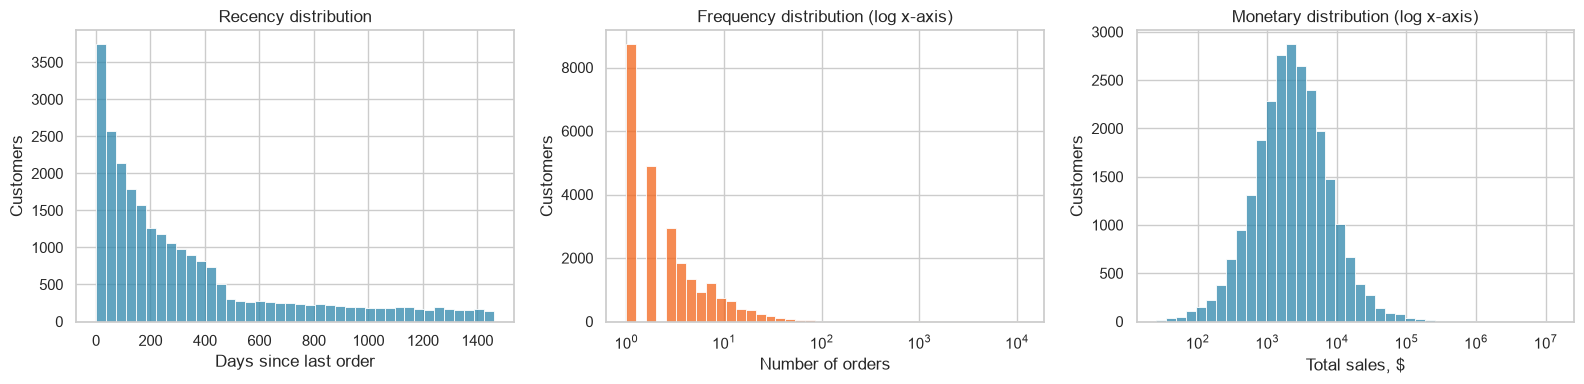

Takeaway: 35.0% of customers placed only one order, while the top customer placed 11,804.


In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(rfm['recency'], bins=40, color='#2E86AB', ax=axes[0])
axes[0].set_title('Recency distribution')
axes[0].set_xlabel('Days since last order')
axes[0].set_ylabel('Customers')

sns.histplot(rfm['frequency'], bins=40, log_scale=True, color='#F26419', ax=axes[1])
axes[1].set_title('Frequency distribution (log x-axis)')
axes[1].set_xlabel('Number of orders')
axes[1].set_ylabel('Customers')

sns.histplot(rfm['monetary'], bins=40, log_scale=True, color='#2E86AB', ax=axes[2])
axes[2].set_title('Monetary distribution (log x-axis)')
axes[2].set_xlabel('Total sales, $')
axes[2].set_ylabel('Customers')

plt.tight_layout()
plt.show()

one_order = (rfm['frequency'] == 1).mean() * 100
print(f'Takeaway: {one_order:.1f}% of customers placed only one order, while the top customer placed {rfm["frequency"].max():,}.')

## 3. Quantile Scoring

Each metric is cut into four equal-size groups with `pd.qcut` and scored 1–4:

- **F and M:** 4 = highest value (best)
- **R:** recency is *inverted* — fewer days since the last order is better, so the labels are `[4, 3, 2, 1]` (4 = most recent)

`pd.qcut` fails when many customers share the same value, because the quartile edges collide. Frequency is the clear case: the 25th percentile and the minimum are both 1.

In [16]:
try:
    pd.qcut(rfm['frequency'], 4, labels=[1, 2, 3, 4])
except ValueError as error:
    print('qcut on raw frequency fails ->', str(error).splitlines()[0])

qcut on raw frequency fails -> Bin edges must be unique: Index([1.0, 1.0, 2.0, 5.0, 11804.0], dtype='float64', name='frequency').


The standard fix is to rank first: `rank(method='first')` gives every customer a unique rank (ties are split by row order), and `qcut` then cuts the ranks into four equal groups.

In [17]:
rfm['r_score'] = pd.qcut(rfm['recency'].rank(method='first'), 4, labels=[4, 3, 2, 1]).astype(int)  # inverted: low recency = 4
rfm['f_score'] = pd.qcut(rfm['frequency'].rank(method='first'), 4, labels=[1, 2, 3, 4]).astype(int)
rfm['m_score'] = pd.qcut(rfm['monetary'].rank(method='first'), 4, labels=[1, 2, 3, 4]).astype(int)

score_ranges = pd.concat({
    'recency (days)': rfm.groupby('r_score')['recency'].agg(['min', 'max']),
    'frequency (orders)': rfm.groupby('f_score')['frequency'].agg(['min', 'max']),
    'monetary ($)': rfm.groupby('m_score')['monetary'].agg(['min', 'max']).round(0),
    'customers per score': rfm.groupby('r_score').size().to_frame('count'),
}, axis=1)
score_ranges

recency (days)       frequency (orders)        monetary ($)              \
             min   max                min    max          min         max   
1            435  1461                  1      1         26.0      1022.0   
2            201   435                  1      2       1022.0      2229.0   
3             72   201                  2      5       2230.0      4922.0   
4              1    72                  5  11804       4922.0  13240047.0   

  customers per score  
                count  
1                6229  
2                6229  
3                6229  
4                6229

Verification: each score group holds exactly 6,229 customers (25%). Recency is inverted correctly — score 4 covers 1–72 days, score 1 covers 435–1,461 days. The top Monetary group starts at **$4,922**, the top Frequency group at **5 orders**.

In [18]:
for metric, score in [('recency', 'r_score'), ('frequency', 'f_score'), ('monetary', 'm_score')]:
    scores_per_value = rfm.groupby(metric)[score].nunique()
    split_values = scores_per_value[scores_per_value > 1]
    affected = rfm[metric].isin(split_values.index).sum()
    print(f'{metric:<10}: {len(split_values):>4} values get more than one score | customers affected: {affected:>6,} ({affected / len(rfm) * 100:.1f}%)')

recency   :    3 values get more than one score | customers affected:    118 (0.5%)
frequency :    3 values get more than one score | customers affected: 14,984 (60.1%)
monetary  :    0 values get more than one score | customers affected:      0 (0.0%)


**Known limitation of `rank(method='first')`.** Frequency has only a few distinct low values (1, 2, 3 …), so customers with *identical* order counts can receive different `f_score` values — **60%** of customers have an `f_score` that is partly decided by tie-breaking. Recency and Monetary are almost tie-free. Section 6 tests how much this changes the final segments.

In [19]:
rfm['rfm_segment'] = rfm['r_score'].astype(str) + rfm['f_score'].astype(str) + rfm['m_score'].astype(str)

print(f'Distinct RFM codes in use : {rfm["rfm_segment"].nunique()} of 64 possible')
rfm['rfm_segment'].value_counts().head(10).rename_axis('rfm_segment').to_frame('customers')

Distinct RFM codes in use : 59 of 64 possible


,customers
rfm_segment,
444,3105
111,1928
344,1592
333,1151
233,1085
211,1001
112,981
121,954
433,868


Codes like `444` (best on all three) and `111` (worst on all three) are the largest groups, because R, F and M move together: customers who buy often also spend more. 64 codes are too many to act on, so they are collapsed into a few named segments next.

## 4. Segment Definition

Six segments are defined with rules on the three scores. Rules are checked **in this order and the first match wins**, so every customer gets exactly one segment.

| # | Segment | Rule | Business reading |
|---|---|---|---|
| 1 | **Champions** | R = 4, F = 4, M = 4 | Bought recently, buy often, spend most |
| 2 | **Loyal** | R ≥ 3, F ≥ 3, M ≥ 3 | Active repeat buyers with solid value, not yet top on all three |
| 3 | **Promising** | R ≥ 3, F ≤ 2 | Recent but few orders: new or still-developing customers |
| 4 | **At Risk** | R ≤ 2, F ≥ 3, M ≥ 3 | Used to buy often and spend well, but have gone quiet |
| 5 | **Lost** | R = 1, F ≤ 2, M ≤ 2 | Long inactive and never valuable |
| 6 | **Needs Attention** | everyone else | Middle of the base: average on most scores and drifting |

In [20]:
SEGMENT_ORDER = ['Champions', 'Loyal', 'Promising', 'Needs Attention', 'At Risk', 'Lost']
segment_colors = {
    'Champions': '#1F77B4', 'Loyal': '#2CA02C', 'Promising': '#17BECF',
    'Needs Attention': '#FF7F0E', 'At Risk': '#D62728', 'Lost': '#7F7F7F',
}


def assign_segment(r: pd.Series, f: pd.Series, m: pd.Series) -> np.ndarray:
    """Rule-based segment labels; np.select returns the first matching rule for each customer."""
    conditions = [
        (r == 4) & (f == 4) & (m == 4),   # Champions
        (r >= 3) & (f >= 3) & (m >= 3),   # Loyal
        (r >= 3) & (f <= 2),              # Promising
        (r <= 2) & (f >= 3) & (m >= 3),   # At Risk
        (r == 1) & (f <= 2) & (m <= 2),   # Lost
    ]
    return np.select(conditions, ['Champions', 'Loyal', 'Promising', 'At Risk', 'Lost'], default='Needs Attention')


rfm['segment'] = pd.Categorical(
    assign_segment(rfm['r_score'], rfm['f_score'], rfm['m_score']),
    categories=SEGMENT_ORDER, ordered=True,
)

print(f'Customers without a segment : {rfm["segment"].isna().sum()}')
print(f'Sum of segment sizes        : {rfm["segment"].value_counts().sum():,} (table has {len(rfm):,} customers)')

Customers without a segment : 0
Sum of segment sizes        : 24,916 (table has 24,916 customers)


Every customer has exactly one segment and the segment sizes add up to the full table.

In [21]:
segment_summary = rfm.groupby('segment', observed=True).agg(
    customer_count=('customer_name', 'count'),
    avg_recency=('recency', 'mean'),
    avg_frequency=('frequency', 'mean'),
    avg_monetary=('monetary', 'mean'),
    median_monetary=('monetary', 'median'),
    total_revenue=('monetary', 'sum'),
).reset_index()

segment_summary['customer_share_%'] = segment_summary['customer_count'] / segment_summary['customer_count'].sum() * 100
segment_summary['revenue_share_%'] = segment_summary['total_revenue'] / segment_summary['total_revenue'].sum() * 100
segment_summary['revenue_vs_customer_share'] = segment_summary['revenue_share_%'] / segment_summary['customer_share_%']

segment_summary.round(1)

,segment,customer_count,avg_recency,avg_frequency,avg_monetary,median_monetary,total_revenue,customer_share_%,revenue_share_%,revenue_vs_customer_share
0,Champions,3105,28.3,27.9,29595.0,12425.6,91892593.0,12.5,60.4,4.8
1,Loyal,4916,99.6,5.7,5880.0,4576.2,28906320.1,19.7,19.0,1.0
2,Promising,3526,99.4,1.4,1452.6,1221.5,5121701.3,14.2,3.4,0.2
3,Needs Attention,6078,355.4,1.8,1624.9,1511.2,9876154.4,24.4,6.5,0.3
4,At Risk,2579,375.6,4.2,4634.5,3942.1,11952490.9,10.4,7.9,0.8
5,Lost,4712,909.1,1.1,920.8,843.9,4338932.5,18.9,2.9,0.2


In [22]:
overall_avg = rfm['monetary'].mean()
champions = segment_summary.set_index('segment').loc['Champions']
lost = segment_summary.set_index('segment').loc['Lost']

print(f'Overall average monetary : ${overall_avg:,.0f}')
print(f'Champions                : {champions["customer_share_%"]:.1f}% of customers -> {champions["revenue_share_%"]:.1f}% of revenue '
      f'(avg ${champions["avg_monetary"]:,.0f} = {champions["avg_monetary"] / overall_avg:.1f}x the overall average)')
print(f'Lost                     : {lost["customer_share_%"]:.1f}% of customers -> {lost["revenue_share_%"]:.1f}% of revenue')

Overall average monetary : $6,104
Champions                : 12.5% of customers -> 60.4% of revenue (avg $29,595 = 4.8x the overall average)
Lost                     : 18.9% of customers -> 2.9% of revenue


**Reading the table.** Champions are **12.5%** of customers but **60.4%** of revenue, and their average Monetary ($29,595) is far above their median ($12,426) — a few very large accounts sit inside this segment. At the other end, Lost customers are **18.9%** of the base but only **2.9%** of revenue.

## 5. Visualizations

### 5.1 Segment sizes

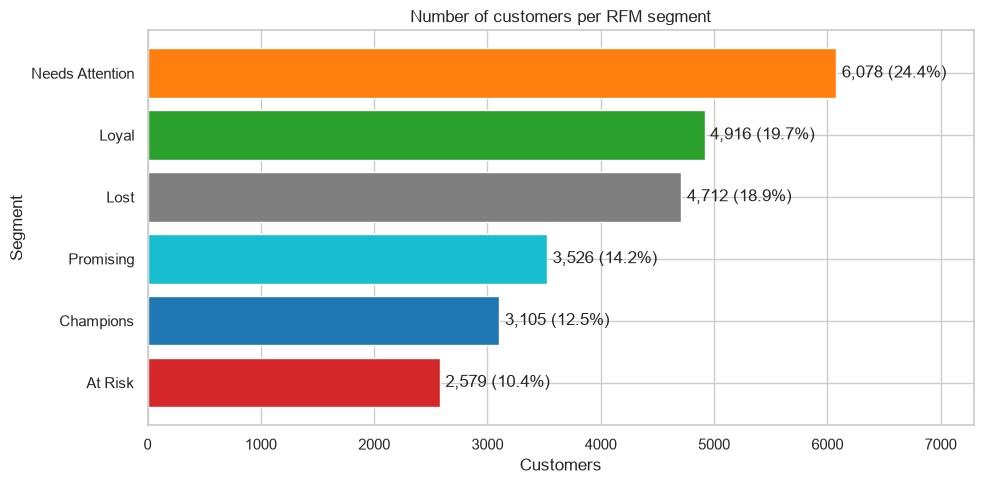

Takeaway: Needs Attention is the largest segment (6,078 customers) and At Risk the smallest (2,579).


In [23]:
bar_data = segment_summary.sort_values('customer_count', ascending=False)

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(bar_data['segment'].astype(str), bar_data['customer_count'], color=[segment_colors[s] for s in bar_data['segment']])
ax.invert_yaxis()
ax.bar_label(ax.containers[0],
             labels=[f'{n:,} ({p:.1f}%)' for n, p in zip(bar_data['customer_count'], bar_data['customer_share_%'])],
             padding=4)
ax.set_xlim(0, bar_data['customer_count'].max() * 1.2)
ax.set_title('Number of customers per RFM segment')
ax.set_xlabel('Customers')
ax.set_ylabel('Segment')
plt.tight_layout()
plt.show()

largest, smallest = bar_data.iloc[0], bar_data.iloc[-1]
print(f'Takeaway: {largest["segment"]} is the largest segment ({largest["customer_count"]:,} customers) and {smallest["segment"]} the smallest ({smallest["customer_count"]:,}).')

Size alone says little about value, so the next chart compares each segment's share of customers with its share of revenue.

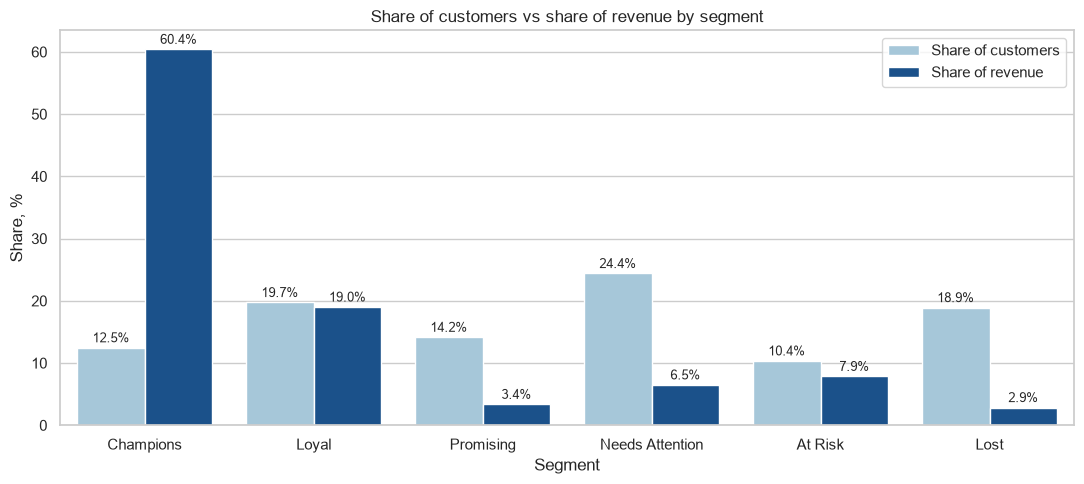

Takeaway: Champions + Loyal are 32.2% of customers and 79.4% of revenue.


In [24]:
share_data = segment_summary.melt(
    id_vars='segment', value_vars=['customer_share_%', 'revenue_share_%'], var_name='metric', value_name='share_%'
)
share_data['metric'] = share_data['metric'].map({'customer_share_%': 'Share of customers', 'revenue_share_%': 'Share of revenue'})

fig, ax = plt.subplots(figsize=(11, 5))
sns.barplot(data=share_data, x='segment', y='share_%', hue='metric', palette=['#9ECAE1', '#08519C'], ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=2, fontsize=9)
ax.set_title('Share of customers vs share of revenue by segment')
ax.set_xlabel('Segment')
ax.set_ylabel('Share, %')
ax.legend(title='')
plt.tight_layout()
plt.show()

print(f'Takeaway: Champions + Loyal are {segment_summary.set_index("segment").loc[["Champions", "Loyal"], "customer_share_%"].sum():.1f}% of customers '
      f'and {segment_summary.set_index("segment").loc[["Champions", "Loyal"], "revenue_share_%"].sum():.1f}% of revenue.')

### 5.2 Recency vs Monetary by segment

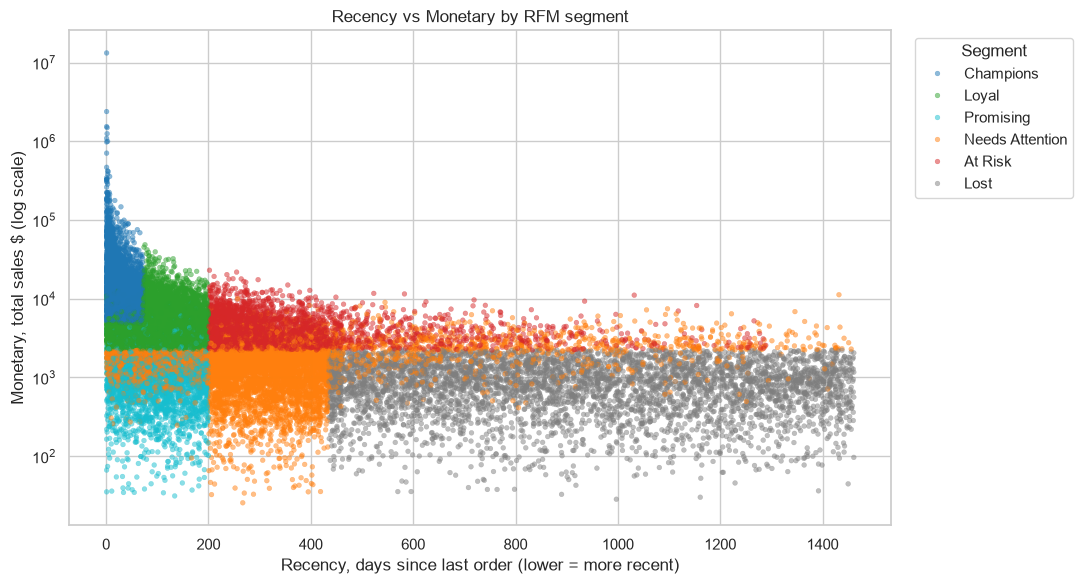

Takeaway: Champions have a median recency of 25 days and median spend of $12,426; Lost customers: 889 days and $844.


In [25]:
fig, ax = plt.subplots(figsize=(11, 6))
sns.scatterplot(data=rfm, x='recency', y='monetary', hue='segment', hue_order=SEGMENT_ORDER,
                palette=segment_colors, s=12, alpha=0.5, edgecolor=None, ax=ax)
ax.set_yscale('log')  # monetary spans $26 to $13M
ax.set_title('Recency vs Monetary by RFM segment')
ax.set_xlabel('Recency, days since last order (lower = more recent)')
ax.set_ylabel('Monetary, total sales $ (log scale)')
ax.legend(title='Segment', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

medians = rfm.groupby('segment', observed=True)[['recency', 'monetary']].median()
print(f'Takeaway: Champions have a median recency of {medians.loc["Champions", "recency"]:.0f} days and median spend of ${medians.loc["Champions", "monetary"]:,.0f}; '
      f'Lost customers: {medians.loc["Lost", "recency"]:.0f} days and ${medians.loc["Lost", "monetary"]:,.0f}.')

### 5.3 Average RFM scores per segment

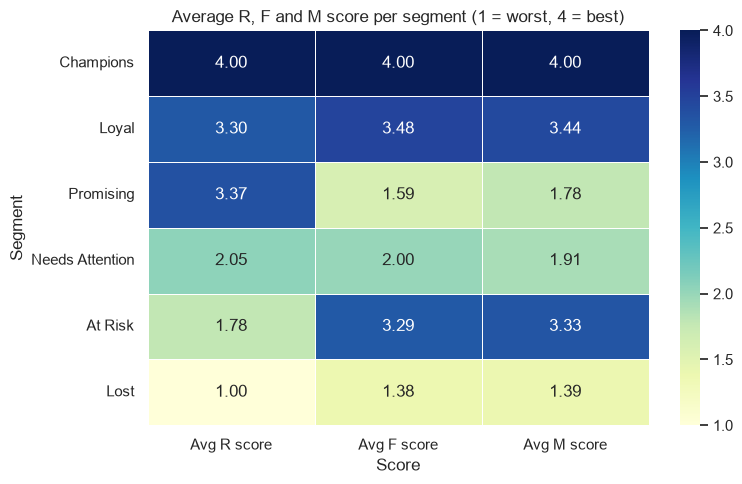

Takeaway: At Risk customers have a high F score (3.29) but a low R score (1.78); Promising is the mirror image (R 3.37, F 1.59).


In [26]:
score_heatmap = rfm.groupby('segment', observed=True)[['r_score', 'f_score', 'm_score']].mean()
score_heatmap.columns = ['Avg R score', 'Avg F score', 'Avg M score']

fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(score_heatmap, annot=True, fmt='.2f', cmap='YlGnBu', vmin=1, vmax=4, linewidths=0.5, ax=ax)
ax.set_title('Average R, F and M score per segment (1 = worst, 4 = best)')
ax.set_xlabel('Score')
ax.set_ylabel('Segment')
plt.tight_layout()
plt.show()

print(f'Takeaway: At Risk customers have a high F score ({score_heatmap.loc["At Risk", "Avg F score"]:.2f}) but a low R score '
      f'({score_heatmap.loc["At Risk", "Avg R score"]:.2f}); Promising is the mirror image (R {score_heatmap.loc["Promising", "Avg R score"]:.2f}, F {score_heatmap.loc["Promising", "Avg F score"]:.2f}).')

### 5.4 Bonus — 3D view of Recency, Frequency and Monetary

In [27]:
rfm_sample = rfm.sample(5000, random_state=42)  # 5,000 of 24,916 points keep the 3D chart light

fig_3d = px.scatter_3d(
    rfm_sample, x='recency', y='frequency', z='monetary',
    color='segment', category_orders={'segment': SEGMENT_ORDER}, color_discrete_map=segment_colors,
    log_y=True, log_z=True, opacity=0.6, hover_name='customer_name',
    title='Customer segments in Recency / Frequency / Monetary space (random sample of 5,000 customers)',
    labels={'recency': 'Recency (days)', 'frequency': 'Frequency (orders, log)', 'monetary': 'Monetary ($, log)', 'segment': 'Segment'},
    height=700,
)
fig_3d.update_traces(marker_size=3)
fig_3d.show()

print('Takeaway: segments form separate zones - Champions sit at low recency / high frequency / high monetary, Lost at high recency / low frequency / low monetary.')

Takeaway: segments form separate zones - Champions sit at low recency / high frequency / high monetary, Lost at high recency / low frequency / low monetary.


## 6. Statistical and Robustness Checks

### 6.1 Are R, F and M independent signals?

In [28]:
rfm[['recency', 'frequency', 'monetary']].corr(method='spearman').round(2)

,recency,frequency,monetary
recency,1.00,-0.60,-0.53
frequency,-0.60,1.00,0.87
monetary,-0.53,0.87,1.00


Spearman is used because all three metrics are heavily skewed. Frequency and Monetary are strongly related (**ρ = 0.87**); Recency is negatively related to both (R–F **-0.60**, R–M **-0.53**).

Part of the F–M link is mechanical, not behavioural: Monetary is the sum of the order lines that Frequency counts, so more orders almost always means more sales. In practice the M score largely repeats the F score. This is an association inside one dataset — it does not show that making a customer order more often would raise their spend.

### 6.2 How concentrated is revenue?

In [29]:
sorted_monetary = rfm['monetary'].sort_values(ascending=False).reset_index(drop=True)
total_revenue = sorted_monetary.sum()

for pct in [1, 10, 20]:
    top_n = int(len(rfm) * pct / 100)
    print(f'Top {pct:>2}% customers ({top_n:>5,}) : {sorted_monetary.head(top_n).sum() / total_revenue * 100:5.1f}% of revenue')

top_customer = rfm.loc[rfm['monetary'].idxmax()]
print(f'\nLargest single customer     : {top_customer["customer_name"]} = ${top_customer["monetary"]:,.0f} '
      f'({top_customer["monetary"] / total_revenue * 100:.1f}% of revenue, {top_customer["frequency"]:,} orders)')

Top  1% customers (  249) :  32.4% of revenue
Top 10% customers (2,491) :  60.4% of revenue
Top 20% customers (4,983) :  73.1% of revenue

Largest single customer     : Cust_18004 Prime Replicas = $13,240,047 (8.7% of revenue, 11,804 orders)


The top 20% of customers produce **73.1%** of revenue and the top 1% alone **32.4%**. One account contributes **8.7%** of all revenue by itself. Rank-based scoring keeps that account from distorting the R/F/M scores (it simply gets a 4), but it does inflate the Champions' revenue share, so Champions revenue should be read as "concentrated in a small number of very large accounts".

### 6.3 Does the Frequency tie-breaking change the segments?

In [30]:
rfm_by_monetary = rfm.sort_values('monetary')  # ties in frequency are now broken by monetary instead of row order
f_score_alt = pd.qcut(rfm_by_monetary['frequency'].rank(method='first'), 4, labels=[1, 2, 3, 4]).astype(int)
f_score_alt = f_score_alt.reindex(rfm.index)

segment_alt = pd.Series(assign_segment(rfm['r_score'], f_score_alt, rfm['m_score']), index=rfm.index)
changed = (segment_alt != rfm['segment'].astype(str))

print(f'Customers whose segment changes : {changed.sum():,} ({changed.mean() * 100:.1f}%)')
print()
comparison = pd.DataFrame({
    'base': rfm['segment'].value_counts(),
    'alt tie-break': segment_alt.value_counts(),
}).reindex(SEGMENT_ORDER)
comparison['difference'] = comparison['alt tie-break'] - comparison['base']
comparison

Customers whose segment changes : 1,592 (6.4%)



,base,alt tie-break,difference
Champions,3105,3151,46
Loyal,4916,5183,267
Promising,3526,3531,5
Needs Attention,6078,5079,-999
At Risk,2579,3056,477
Lost,4712,4916,204


Changing how ties are broken moves **6.4%** of customers into a different segment, and the change is not evenly spread. **Champions** (3,105 → 3,151) and **Promising** (3,526 → 3,531) are almost unchanged. The middle of the base moves: **Needs Attention** shrinks from 6,078 to 5,079, while **At Risk** grows from 2,579 to 3,056 (+18%), **Loyal** and **Lost** also gain. Customers with 1–2 orders sit on the F boundaries, so they are the ones who switch.

> The extremes (Champions, Promising) are stable; the size of the **At Risk** and **Needs Attention** segments depends on the tie-break rule and should be read as approximate.

## 7. Marketing Actions by Segment

| Segment | Size and value | Profile | Marketing actions | KPI to track |
|---|---|---|---|---|
| **Champions** | 3,105 customers (12.5%), 60.4% of revenue | Avg recency 28 days, 27.9 orders, $29,595 | Recognise, do not discount: they already buy at full price. VIP programme with named account manager for the largest accounts; early access to new products; referral and testimonial requests. | Share still in R = 4 next quarter; revenue per customer |
| **Loyal** | 4,916 customers (19.7%), 19.0% of revenue | Avg recency 100 days, 5.7 orders, $5,880 | Move them toward Champions: volume-tier incentives aimed at the Champions entry level (5+ orders or $4,922+ total), product bundles and cross-sell based on past orders. | Share promoted to Champions; average order value |
| **Promising** | 3,526 customers (14.2%), 3.4% of revenue | Avg recency 99 days, only 1.4 orders, $1,453 | Win the next order while the memory is fresh: onboarding email series, reorder reminders and a small time-limited incentive on order 2 or 3. | Second-order rate; days between order 1 and 2 |
| **Needs Attention** | 6,078 customers (24.4%), 6.5% of revenue | Avg recency 355 days, 1.8 orders, $1,625 | Largest segment and mixed profile, so test before spending: A/B test a reminder email vs a limited-time offer, and send a short survey to find what blocks the next order. | Reactivation rate of each test arm vs control |
| **At Risk** | 2,579 customers (10.4%), 7.9% of revenue | Avg recency 376 days, but 4.2 orders and $4,635 | Highest-priority win-back: personal outreach from the sales team for the largest accounts, a "we miss you" offer and a feedback call on why they stopped. | Share ordering again within 90 days; recovered revenue |
| **Lost** | 4,712 customers (18.9%), 2.9% of revenue | Avg recency 909 days, 1.1 orders, $921 | Low-cost, automated reactivation only: one short email sequence, then stop contacting non-responders to save budget. No account-manager time. | Response rate; cost per reactivated customer |

Priority by value at stake: **At Risk** first (strong history, recoverable), **Promising** second (cheapest to grow), **Champions** continuous (protect 60% of revenue).

## 8. Export for the Marketing Team

In [31]:
export_columns = ['customer_name', 'recency', 'frequency', 'monetary', 'r_score', 'f_score', 'm_score', 'rfm_segment', 'segment']

rfm_report = rfm[export_columns].sort_values(['segment', 'monetary'], ascending=[True, False]).reset_index(drop=True)
rfm_report['monetary'] = rfm_report['monetary'].round(2)
rfm_report.to_csv('rfm_segments_report.csv', index=False, encoding='utf-8-sig')  # utf-8-sig opens correctly in Excel

check = pd.read_csv('rfm_segments_report.csv')
print(f'Exported rows x columns : {check.shape[0]:,} x {check.shape[1]}')
check.head(5)

Exported rows x columns : 24,916 x 9


,customer_name,recency,frequency,monetary,r_score,f_score,m_score,rfm_segment,segment
0,Cust_18004 Prime Replicas,1,11804,13240046.58,4,4,4,444,Champions
1,Cust_34145 Global Enterprises,1,2354,2385288.71,4,4,4,444,Champions
2,Cust_06604 Alpha Shops,1,717,1537544.21,4,4,4,444,Champions
3,Cust_09572 First Enterprises,2,1509,1488625.94,4,4,4,444,Champions
4,Cust_26210 Pacific Replicas,2,1207,1250123.80,4,4,4,444,Champions


## 9. Final Summary



### Key Findings



1. **Revenue is highly concentrated in a small group.** Champions are **12.5%** of customers (3,105) but **60.4%** of revenue; their average spend of $29,595 is 4.8x the overall average of $6,104.
2. **The top of the base carries the business.** Champions + Loyal are **32.2%** of customers and **79.4%** of revenue. The top 20% of customers by spend give **73.1%**, and a single account gives **8.7%**.
3. **A strong but quiet group is recoverable.** At Risk is **10.4%** of customers (2,579) with 4.2 orders on average, but they last ordered 376 days ago. They hold **7.9%** of revenue ($11,952,491) that is at stake.
4. **Over a third of customers have a single order.** 35.0% of customers placed one order only (median Frequency = 2); some of them are recent first-time buyers (Promising), the rest are inactive. Lost customers are 18.9% of the base but only 2.9% of revenue, so heavy spend on them is not justified.
5. **R, F and M are not three independent signals.** Frequency and Monetary correlate at ρ = 0.87 partly by construction, while Recency is the most independent dimension (R–F -0.60, R–M -0.53). Association only; it does not show cause.
6. **The extreme segments are stable, the middle is not.** Changing the Frequency tie-break moves 6.4% of customers to another segment: Champions (3,105 → 3,151) barely change, but At Risk grows by 18% and Needs Attention shrinks by 16%.



### Business Recommendations



- **Protect:** Champions (and the largest accounts inside them) get recognition and account management, not discounts.
- **Grow:** Loyal → Champions with volume incentives; Promising → second and third order with onboarding and reorder reminders.
- **Win back:** At Risk first, with personal outreach; Needs Attention through A/B-tested reminders before it drifts into At Risk.
- **Save budget:** Lost customers get one automated email sequence only.
- Full action table with KPIs: section 7.
